## **Testing combinations to make interseccional groups**

In [ ]:
from itertools import combinations

In [ ]:
sensitive_features = ["age", "gender", "race"]

res = []
for i in range(1, len(sensitive_features) + 1):
    c = list(combinations(sensitive_features, i))
    print(c)
    res.extend(c)

In [ ]:
res

In [ ]:
joined = ["_".join(pairs) for pairs in res]

In [ ]:
joined

## **Test Basic Fairness Engine**

In [1]:
import sys
sys.path.append("../src")

In [2]:
from fairness import FairnessEngine
from utils import load_data

In [3]:
df = load_data("../data/hcc_dataset.csv")

In [4]:
df

,gender,symptoms,alcohol,hbsag,hbeag,hbcab,hcvab,cirrhosis,endemic,smoking,...,alp,tp,creatinine,nodules,major_dim,dir_bil,iron,sat,ferritin,class
0,male,no,yes,no,no,no,no,yes,no,yes,...,150.0,7.1,0.70,1.0,3.5,0.5,NaN,NaN,NaN,lives
1,female,NaN,no,no,no,no,yes,yes,NaN,NaN,...,NaN,NaN,NaN,1.0,1.8,NaN,NaN,NaN,NaN,lives
2,male,no,yes,yes,no,yes,no,yes,no,yes,...,109.0,7.0,2.10,5.0,13.0,0.1,28.0,6.0,16.0,lives
3,male,yes,yes,no,no,no,no,yes,no,yes,...,174.0,8.1,1.11,2.0,15.7,0.2,NaN,NaN,NaN,dies
4,male,yes,yes,yes,no,yes,no,yes,no,yes,...,109.0,6.9,1.80,1.0,9.0,NaN,59.0,15.0,22.0,lives
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,female,no,yes,NaN,NaN,NaN,yes,yes,no,yes,...,109.0,7.6,0.70,5.0,3.0,NaN,NaN,NaN,NaN,lives
161,female,yes,no,NaN,NaN,NaN,NaN,yes,no,no,...,280.0,6.7,0.70,1.0,2.2,2.3,NaN,NaN,NaN,dies
162,male,no,yes,no,no,no,no,yes,no,yes,...,181.0,7.5,1.46,5.0,18.6,NaN,NaN,NaN,NaN,lives
163,male,no,yes,yes,no,yes,yes,yes,yes,yes,...,170.0,8.4,0.74,5.0,18.0,NaN,NaN,NaN,NaN,dies


In [6]:
fair_engine = FairnessEngine(df, 
                              sensitive_features=["gender", "diabetes"],
                              target="class")

In [7]:
fair_engine.get_sensitive_features()

['gender', 'diabetes']

In [8]:
fair_engine.get_sensitive_groups()

['gender', 'diabetes', 'gender_diabetes']

In [ ]:
#Dummy pivot table: DO NOT RUN

pd.pivot_table(
    data,               # our df
    values=None,        # values to aggregate (numeric or categorical for counts)
    index=None,         # what we want in rows, usually grouping keys  
    columns=None,       # what gets passed in columns
    aggfunc='mean',     # how to summarize the data: mean, sum, count, size, min, max
    fill_value=None,    # what to put in combinations that do not exist
    margins=False,      # if true, adds total (row and colum)
    dropna=True         # drops columns in output that are all NaN
)

In [9]:
import pandas as pd

pd.pivot_table(
    df,
    columns=["gender", "alcohol"],
    aggfunc="size"
)

gender  alcohol
female  no          21
        yes         11
male    no          22
        yes        111
dtype: int64

In [10]:
df.groupby(["class", "gender", "alcohol"]).size().reset_index(name="count")

,class,gender,alcohol,count
0,dies,female,no,7
1,dies,female,yes,4
2,dies,male,no,8
3,dies,male,yes,44
4,lives,female,no,14
5,lives,female,yes,7
6,lives,male,no,14
7,lives,male,yes,67


In [11]:
df.pivot_table(
    index="class", 
    columns=["gender", "alcohol", "symptoms", "ps"],
    aggfunc="size"
)

gender   female                                                            \
alcohol      no                                 yes                         
symptoms     no    yes                           no                         
ps       active active ambulatory restricted active ambulatory restricted   
class                                                                       
dies        1.0    1.0        3.0        2.0    1.0        NaN        NaN   
lives       3.0    5.0        3.0        1.0    3.0        2.0        1.0   

gender                         male  ...                               \
alcohol                          no  ...               yes              
symptoms                 yes     no  ...        yes     no              
ps       selfcare ambulatory active  ... restricted active ambulatory   
class                                ...                                
dies          1.0        2.0    1.0  ...        1.0    2.0        1.0   
lives         NaN        1.0    6.0  ...        4.0   18.0        4.0   

gender                                                                       
alcohol                                                                      
symptoms                        yes                                          
ps       restricted selfcare active ambulatory disabled restricted selfcare  
class                                                                        
dies            2.0      1.0    8.0        8.0      4.0        8.0      9.0  
lives           3.0      1.0   14.0        6.0      NaN        6.0      4.0  

[2 rows x 24 columns]

In [12]:
import pandas as pd

In [13]:
pivot = pd.pivot_table(
    df,
    index="class",
    columns=["gender", "alcohol", "symptoms"],
    aggfunc="size",
    fill_value=0
)

In [14]:
pivot

gender   female             male            
alcohol      no     yes       no     yes    
symptoms     no yes  no yes   no yes  no yes
class                                       
dies          1   6   2   2    3   5   6  37
lives         3   9   6   1    6   4  26  30

In [15]:
pivot_rate = round(pivot / pivot.values.sum() * 100, 2)

In [16]:
pivot_rate

gender   female                    male                    
alcohol      no         yes          no          yes       
symptoms     no   yes    no   yes    no   yes     no    yes
class                                                      
dies       0.68  4.08  1.36  1.36  2.04  3.40   4.08  25.17
lives      2.04  6.12  4.08  0.68  4.08  2.72  17.69  20.41

In [17]:
pivot_rate.values.sum()

99.99000000000001

In [18]:
sensitive_groups = ['gender', 'diabetes', 'gender_diabetes_bla_ble_bli']

In [19]:
cenas = {}
for g in sensitive_groups:
    cenas[g] = g.split("_")

In [20]:
cenas

{'gender': ['gender'],
 'diabetes': ['diabetes'],
 'gender_diabetes_bla_ble_bli': ['gender', 'diabetes', 'bla', 'ble', 'bli']}

## **Trying Target Rate by Group**

In [1]:
import sys
sys.path.append("../src")

In [21]:
from fairness import FairnessEngine
from utils import load_data

In [22]:
df = load_data("../data/hcc_dataset.csv")

In [24]:
fair_engine = FairnessEngine(df, 
                                    sensitive_features=["gender", "alcohol", "endemic"],
                                    target="class")

In [25]:
fair_engine.get_sensitive_features()

['gender', 'alcohol', 'endemic']

In [26]:
fair_engine.get_sensitive_groups()

['gender',
 'alcohol',
 'endemic',
 'gender_alcohol',
 'gender_endemic',
 'alcohol_endemic',
 'gender_alcohol_endemic']

In [27]:
fair_engine.target_rate_by_group_table(group="gender_alcohol_endemic")

gender  female              male                   
alcohol     no         yes    no          yes      
endemic     no   yes    no    no   yes     no   yes
class                                              
dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

In [28]:
fair_engine.target_rate_by_group_table(group="gender", target="symptoms")

gender,female,male
symptoms,,
no,8.16,27.89
yes,12.24,51.70


### **Testing without providing a target in init**

In [31]:
fe = FairnessEngine(df, 
                      sensitive_features=["gender", "alcohol", "endemic"],
                    )

In [32]:
fe.target_rate_by_group_table(group="gender", target="alcohol")

gender,female,male
alcohol,,
no,12.73,13.33
yes,6.67,67.27


In [33]:
fe.get_sensitive_features()

['gender', 'alcohol', 'endemic']

In [34]:
fe.get_sensitive_groups()

['gender',
 'alcohol',
 'endemic',
 'gender_alcohol',
 'gender_endemic',
 'alcohol_endemic',
 'gender_alcohol_endemic']

## **Trying group proportions**

In [35]:
fair_engine.group_proportions_table("gender")

gender
female    19.39
male      80.61
dtype: float64

In [36]:
fair_engine.group_proportions_table("alcohol")

alcohol
no     26.06
yes    73.94
dtype: float64

In [37]:
fair_engine.group_proportions_table("gender_alcohol")

alcohol,no,yes
gender,,
female,12.73,6.67
male,13.33,67.27


In [38]:
fair_engine.group_proportions_table("gender_alcohol_endemic")

alcohol     no          yes      
endemic     no   yes     no   yes
gender                           
female   10.32  1.59   5.56  0.00
male     11.90  1.59  64.29  4.76

In [39]:
df

,gender,symptoms,alcohol,hbsag,hbeag,hbcab,hcvab,cirrhosis,endemic,smoking,...,alp,tp,creatinine,nodules,major_dim,dir_bil,iron,sat,ferritin,class
0,male,no,yes,no,no,no,no,yes,no,yes,...,150.0,7.1,0.70,1.0,3.5,0.5,NaN,NaN,NaN,lives
1,female,NaN,no,no,no,no,yes,yes,NaN,NaN,...,NaN,NaN,NaN,1.0,1.8,NaN,NaN,NaN,NaN,lives
2,male,no,yes,yes,no,yes,no,yes,no,yes,...,109.0,7.0,2.10,5.0,13.0,0.1,28.0,6.0,16.0,lives
3,male,yes,yes,no,no,no,no,yes,no,yes,...,174.0,8.1,1.11,2.0,15.7,0.2,NaN,NaN,NaN,dies
4,male,yes,yes,yes,no,yes,no,yes,no,yes,...,109.0,6.9,1.80,1.0,9.0,NaN,59.0,15.0,22.0,lives
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,female,no,yes,NaN,NaN,NaN,yes,yes,no,yes,...,109.0,7.6,0.70,5.0,3.0,NaN,NaN,NaN,NaN,lives
161,female,yes,no,NaN,NaN,NaN,NaN,yes,no,no,...,280.0,6.7,0.70,1.0,2.2,2.3,NaN,NaN,NaN,dies
162,male,no,yes,no,no,no,no,yes,no,yes,...,181.0,7.5,1.46,5.0,18.6,NaN,NaN,NaN,NaN,lives
163,male,no,yes,yes,no,yes,yes,yes,yes,yes,...,170.0,8.4,0.74,5.0,18.0,NaN,NaN,NaN,NaN,dies


In [40]:
import pandas as pd

pivot = pd.pivot_table(
    df,
    index=["gender", "alcohol", "endemic"],
    columns="class",
    aggfunc="size",
    fill_value=0
)

In [41]:
pivot

class                   dies  lives
gender alcohol endemic             
female no      no          6      7
               yes         0      2
       yes     no          1      6
male   no      no          7      8
               yes         0      2
       yes     no         32     49
               yes         2      4

In [42]:
fair_engine.target_rate_by_group_table("gender_alcohol_endemic")

gender  female              male                   
alcohol     no         yes    no          yes      
endemic     no   yes    no    no   yes     no   yes
class                                              
dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

In [43]:
pivot_df = fair_engine.target_rate_by_group_table("gender_alcohol_endemic")

In [44]:
pivot_df

gender  female              male                   
alcohol     no         yes    no          yes      
endemic     no   yes    no    no   yes     no   yes
class                                              
dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

## **Testing internal profiler?**

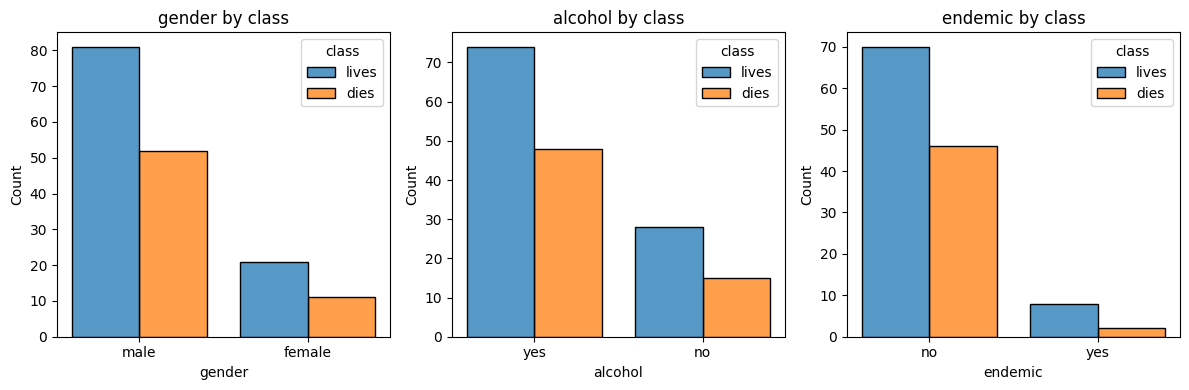

In [46]:
fair_engine.profiler.plot_mult_histogram(cols=3, col_names=fair_engine.get_sensitive_features(), hue="class")

In [47]:
pivot_df

gender  female              male                   
alcohol     no         yes    no          yes      
endemic     no   yes    no    no   yes     no   yes
class                                              
dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

In [48]:
from profiler import DataProfiler
test_profile = DataProfiler(df)

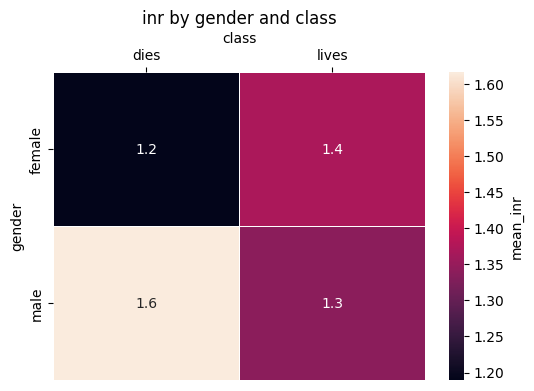

In [49]:
test_profile.plot_pivot_table(values="inr", index="gender", columns="class", aggfunc="mean")

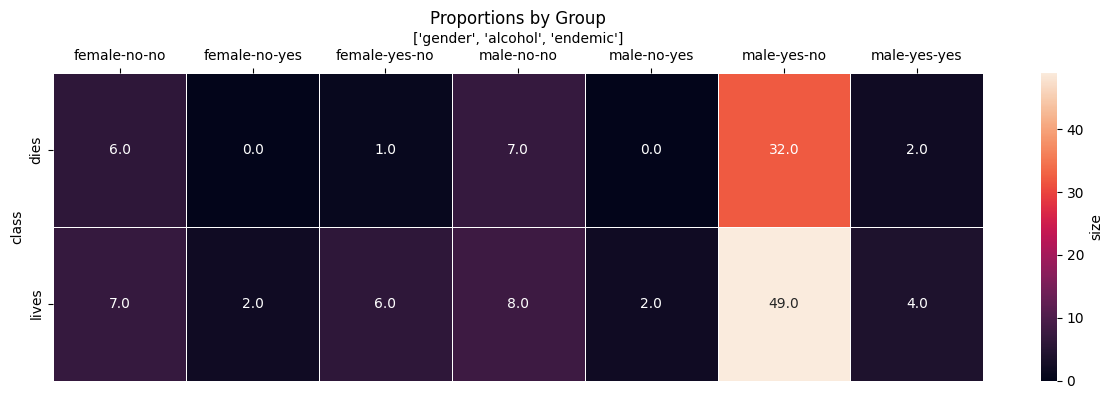

In [50]:
fair_engine.profiler.plot_pivot_table(index="class", columns=["gender", "alcohol", "endemic"], aggfunc="size", title="Proportions by Group", figsize=(15, 4))

## **Implementation Ideas**

All of these can be made with profiler:
1. Histogram (simple) of sensitive features (plot_sensitive_groups, target=None) (this could include all groups) ✅
2. Histogram of sensitive features by class (solved with first) ✅
 -- For 1 and 2, it might be possible to use plot_mult to plot either cat and num features
3. Histogram of another feature by sensitive features (plot_feature_by_group) (this could include all groups)
    -- 3 assumes senstive features are categorical, maybe we can adapt
4. Plot pivot tables (group_proportions and target_rate) (this is best used as a flag to plot in respective method, then we can check for other usage?) --> ✅

## **Testing Visualizations**

In [51]:
import sys
sys.path.append("../src")

In [52]:
from fairness import FairnessEngine
from profiler import DataProfiler
from utils import load_data

In [53]:
df = load_data("../data/hcc_dataset.csv")

In [55]:
toy_profiler = DataProfiler(df, target="class")

engine = FairnessEngine(df, 
                                    sensitive_features=["gender", "alcohol", "endemic"],
                                    target="class")

In [56]:
pivot_df = engine.target_rate_by_group_table(group="gender_alcohol_endemic")

In [57]:
pivot_df

gender  female              male                   
alcohol     no         yes    no          yes      
endemic     no   yes    no    no   yes     no   yes
class                                              
dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

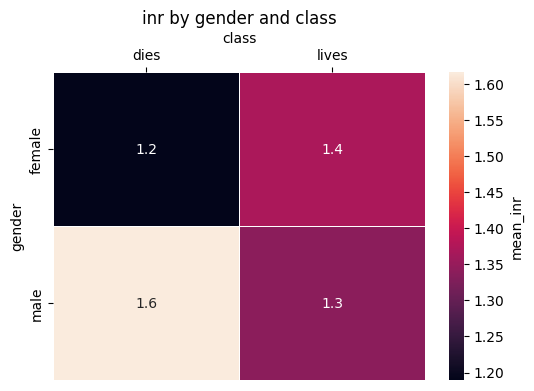

In [58]:
toy_profiler.plot_pivot_table(values="inr", index="gender", columns="class", aggfunc="mean")

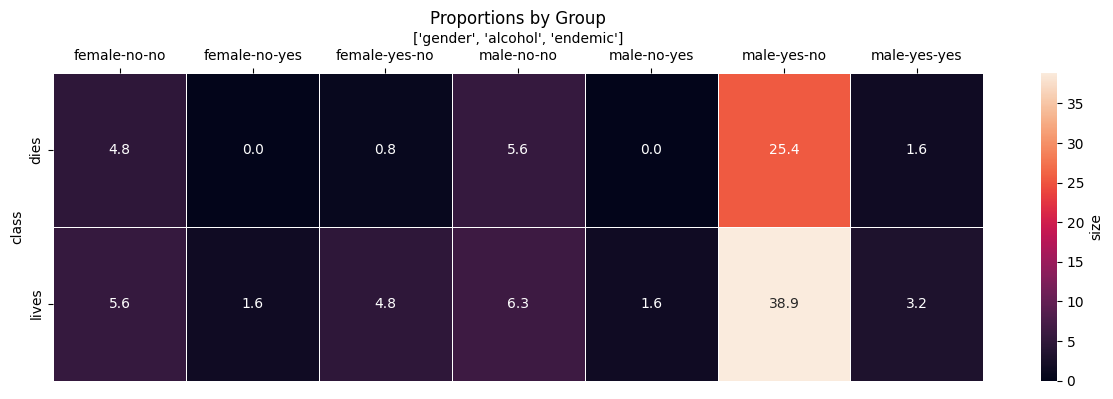

In [59]:
engine.profiler.plot_pivot_table(index="class", columns=["gender", "alcohol", "endemic"], aggfunc="size", title="Proportions by Group", plot_percent=True, figsize=(15, 4))

In [60]:
pivot_df

gender  female              male                   
alcohol     no         yes    no          yes      
endemic     no   yes    no    no   yes     no   yes
class                                              
dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

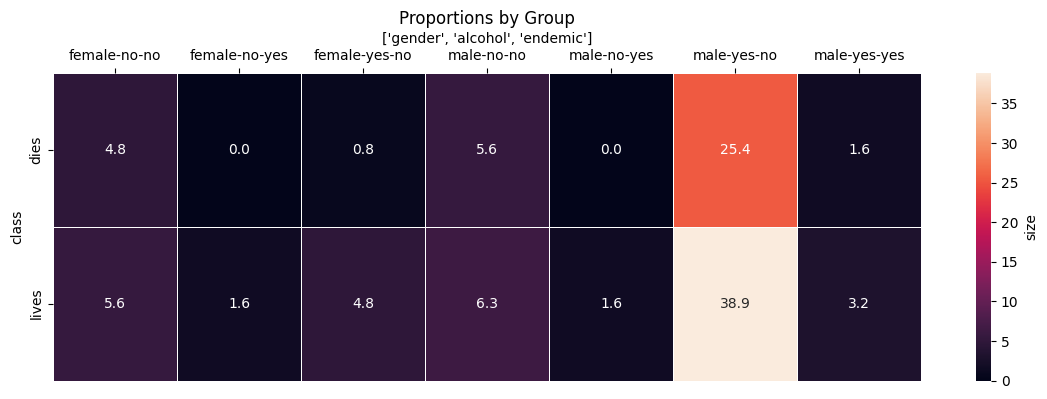

In [61]:
pivot_rate = engine.target_rate_by_group_table(group="gender_alcohol_endemic", plot_tab=True)

In [62]:
pivot_rate

gender  female              male                   
alcohol     no         yes    no          yes      
endemic     no   yes    no    no   yes     no   yes
class                                              
dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

In [63]:
engine.group_proportions_table("gender_alcohol_endemic")

alcohol     no          yes      
endemic     no   yes     no   yes
gender                           
female   10.32  1.59   5.56  0.00
male     11.90  1.59  64.29  4.76

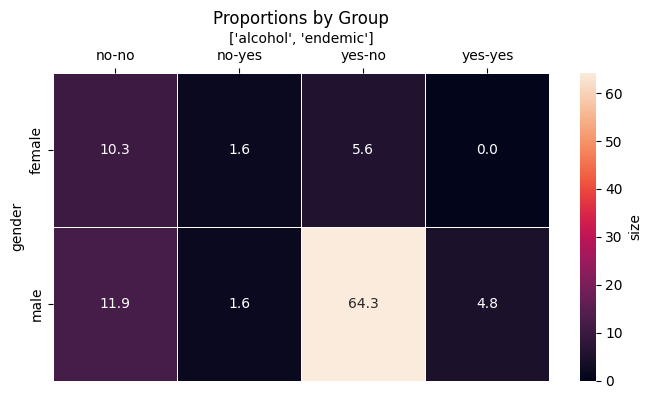

alcohol     no          yes      
endemic     no   yes     no   yes
gender                           
female   10.32  1.59   5.56  0.00
male     11.90  1.59  64.29  4.76

In [64]:
engine.group_proportions_table("gender_alcohol_endemic", plot_tab=True)

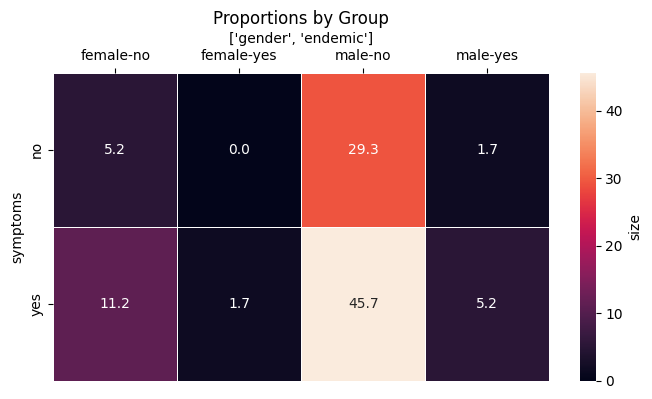

gender   female         male      
endemic      no   yes     no   yes
symptoms                          
no         5.17  0.00  29.31  1.72
yes       11.21  1.72  45.69  5.17

In [65]:
engine.target_rate_by_group_table(group="gender_endemic", target="symptoms", plot_tab=True)

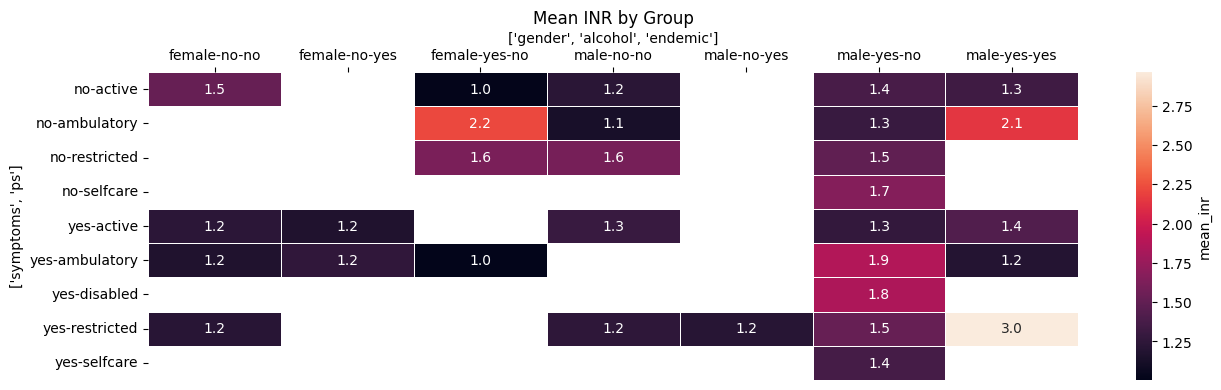

In [66]:
# It's important to document the profiler (no need to add multiple methods to FairnessProfile...)
engine.profiler.plot_pivot_table(values="inr",
                                           index=["symptoms", "ps"], 
                                           columns=["gender", "alcohol", "endemic"],
                                           aggfunc="mean", 
                                           title="Mean INR by Group",
                                           figsize=(15, 4))

## **Testing barplots of sensitive groups**

In [1]:
import sys
sys.path.append("../src")

In [2]:
from utils import load_data
from profiler import DataProfiler
from fairness import FairnessEngine

In [3]:
df = load_data(path="../data/hcc_dataset.csv")

In [4]:
fe = FairnessEngine(df=df,
                    sensitive_features=["gender", "alcohol", "endemic"],
                    target="class")

In [5]:
fe.get_sensitive_groups()

['gender',
 'alcohol',
 'endemic',
 'gender_alcohol',
 'gender_endemic',
 'alcohol_endemic',
 'gender_alcohol_endemic']

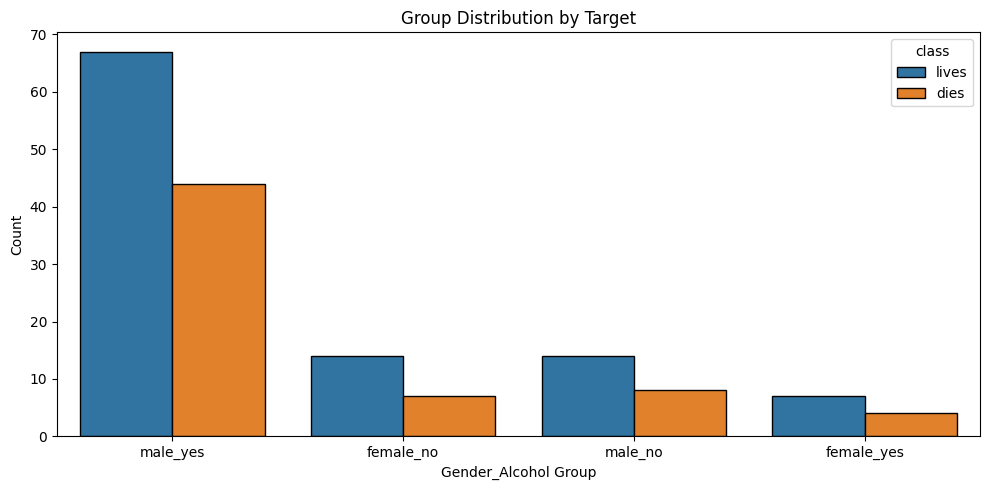

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(data=fe.fairness_df, x="gender_alcohol", hue="class", edgecolor="black")

plt.title("Group Distribution by Target")
plt.xlabel("Gender_Alcohol Group")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

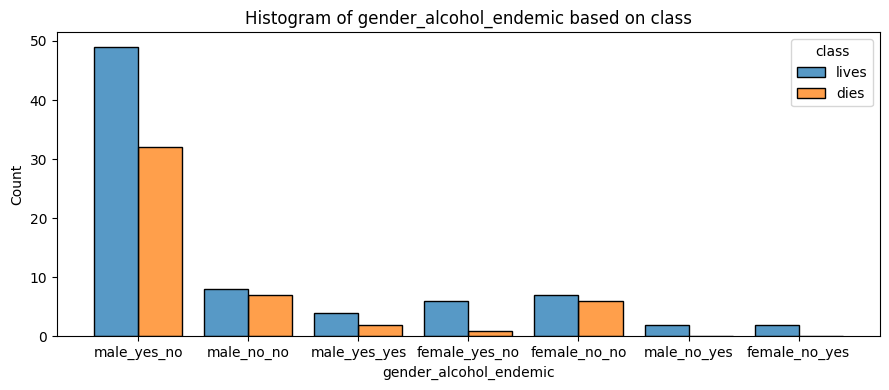

In [7]:
fe.fairness_profiler.plot_histogram(x="gender_alcohol_endemic", hue="class", multiple="dodge", figsize=(9, 4))

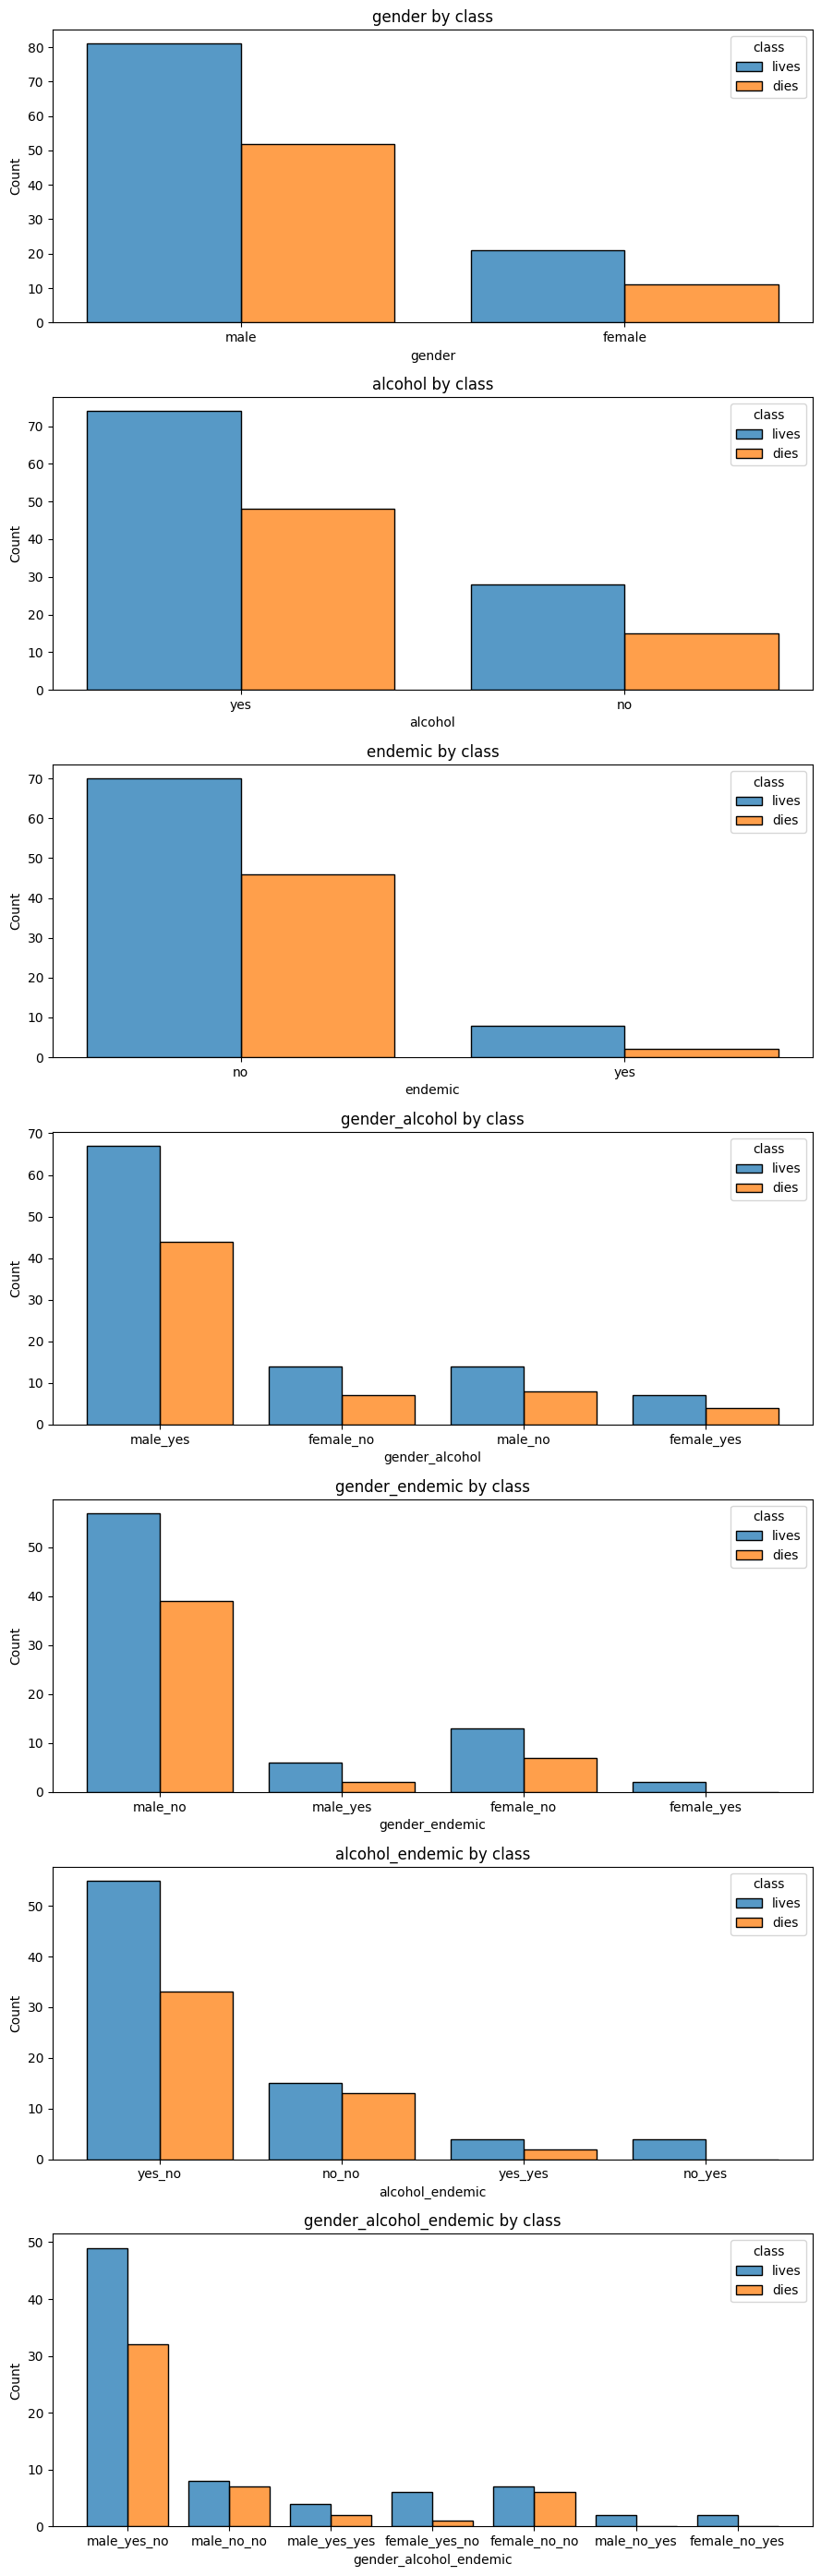

In [8]:
import math
groups = fe.get_sensitive_groups()
default_cols = len(groups)
cols = math.ceil(len(groups)/default_cols)
fe.fairness_profiler.plot_mult_histogram(col_names=groups, hue="class", cols=cols, subplot_size=(9,4))

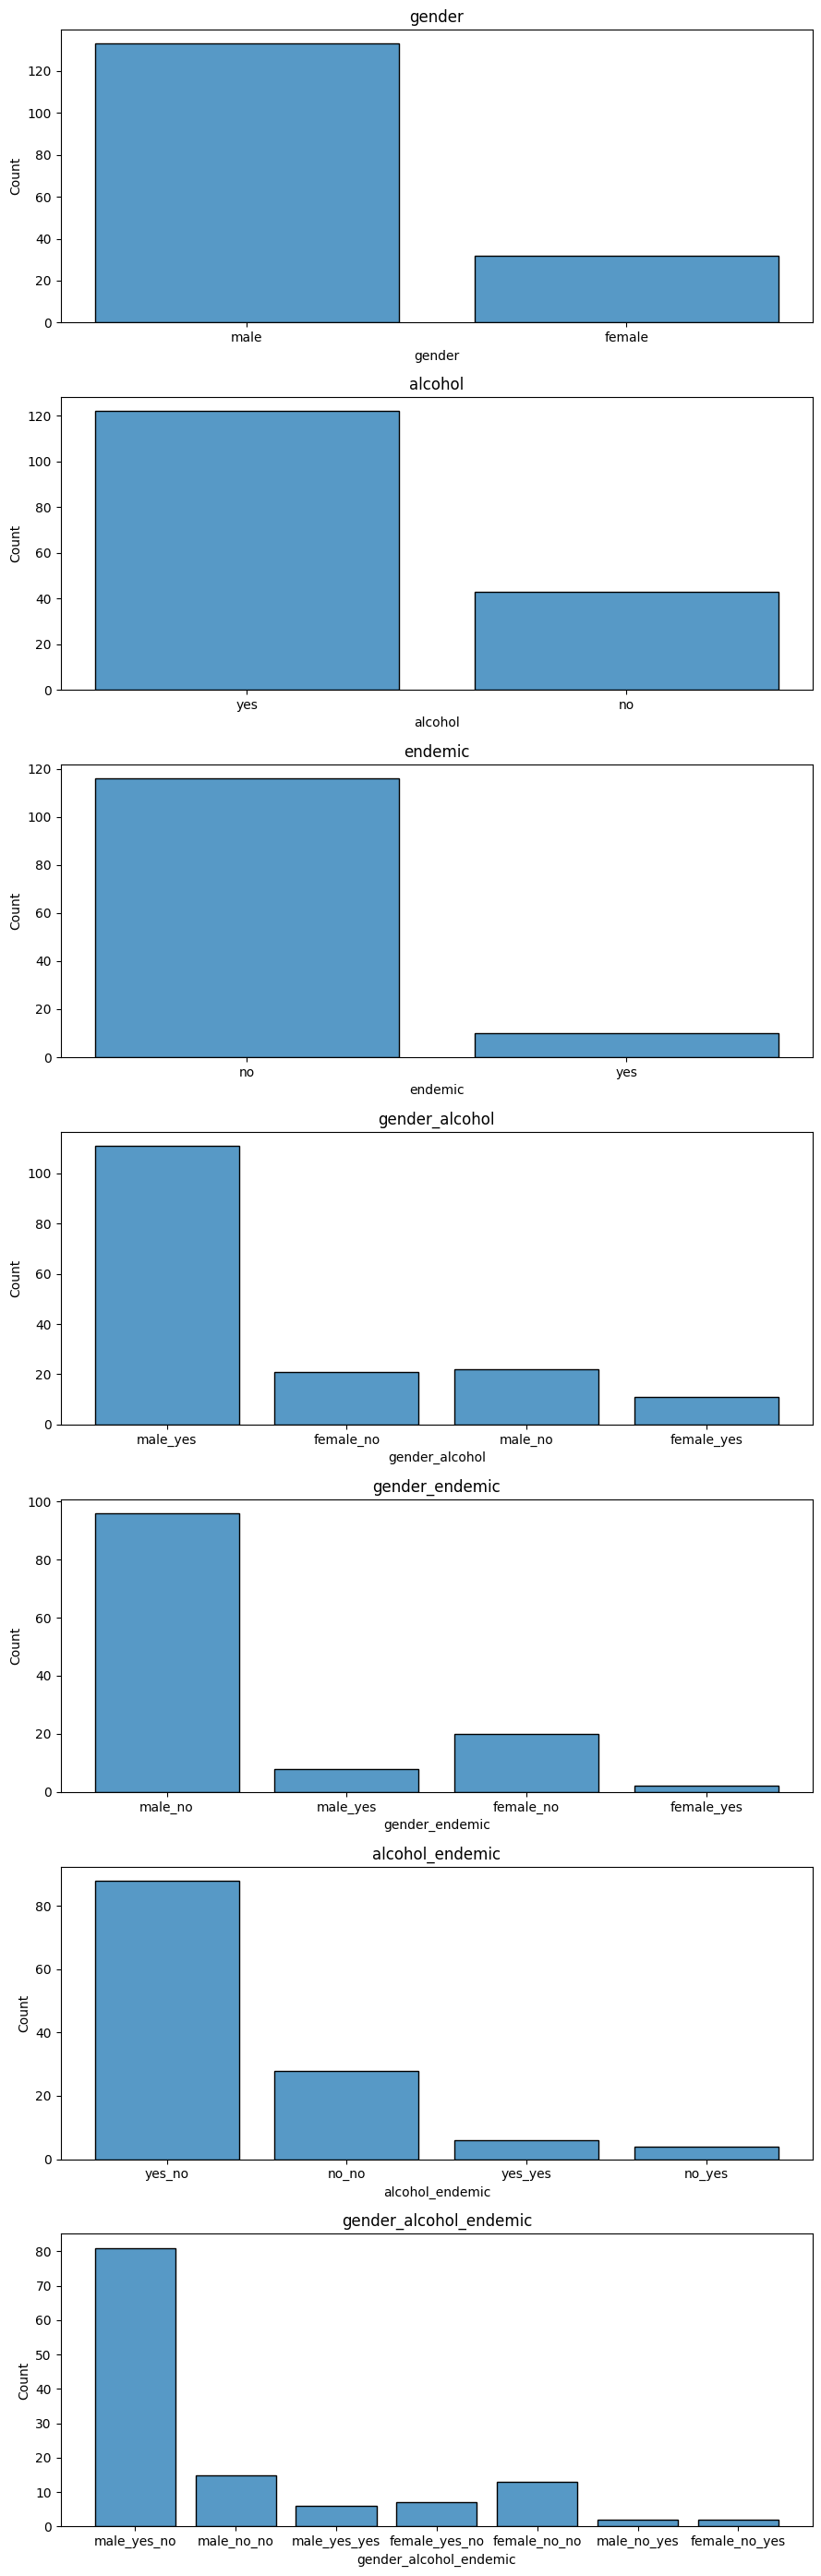

In [9]:
fe.plot_sensitive_groups(groups="all")

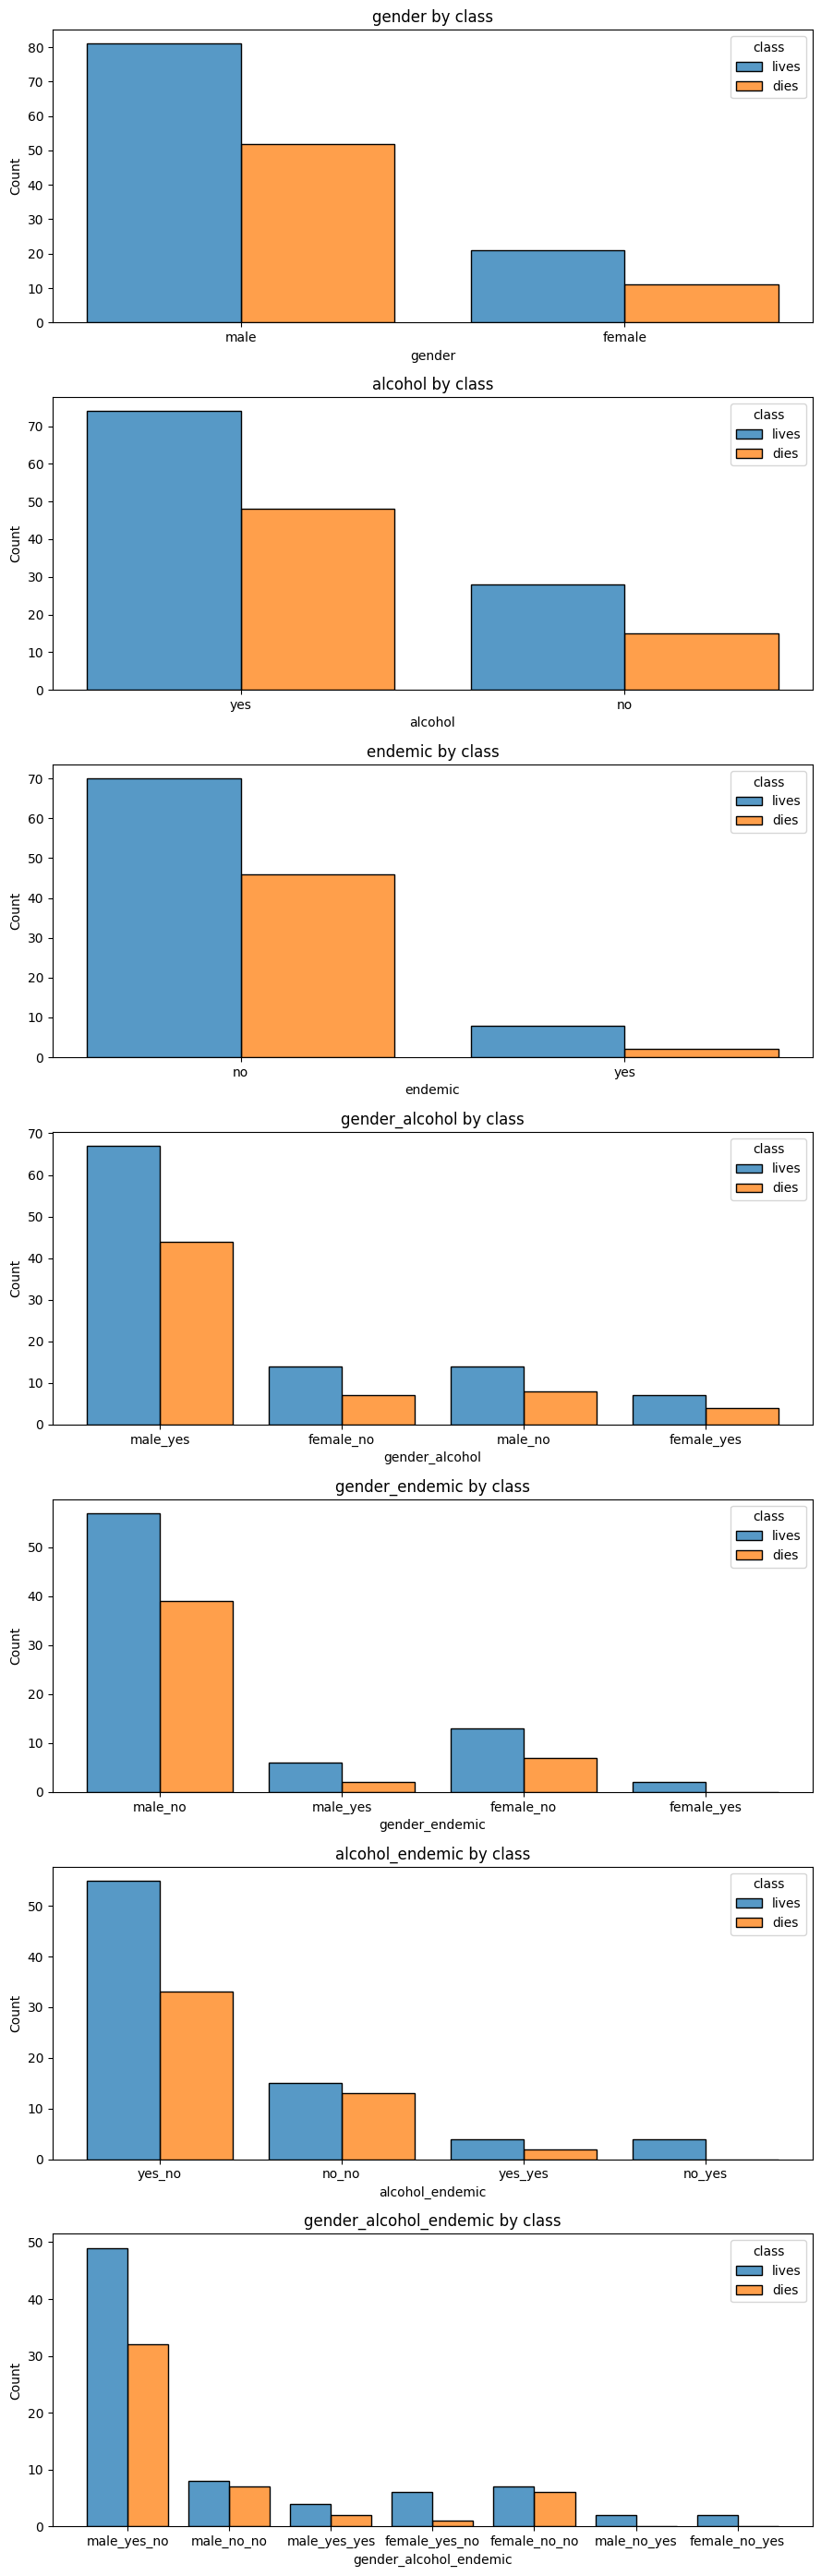

In [10]:
fe.plot_sensitive_groups(groups="all", target="class")

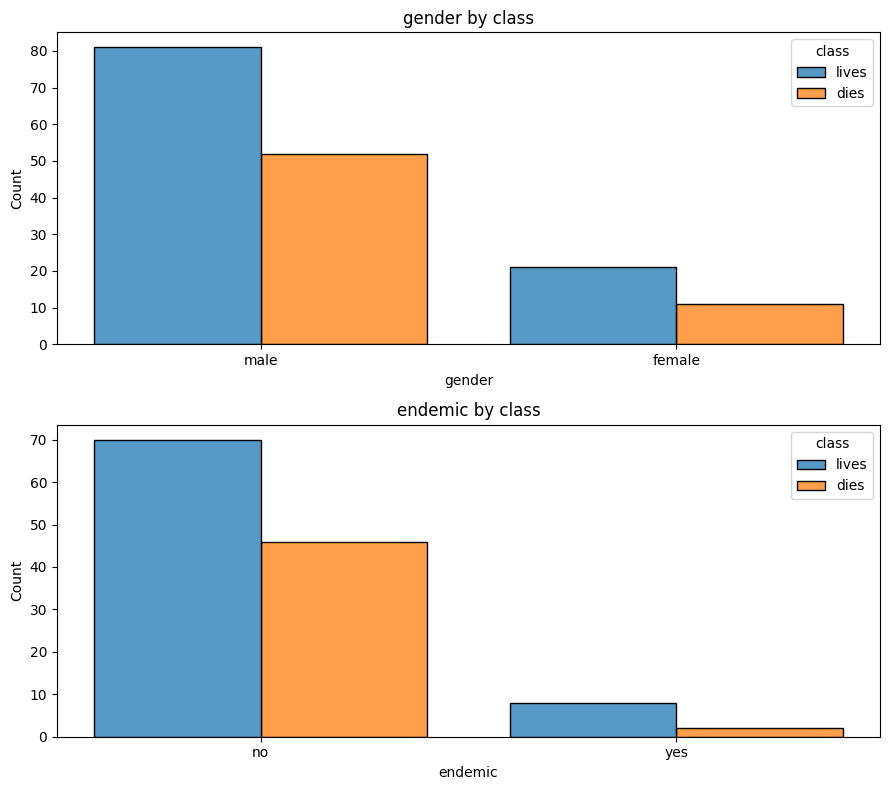

In [11]:
fe.plot_sensitive_groups(groups=["gender", "endemic"], target="class")

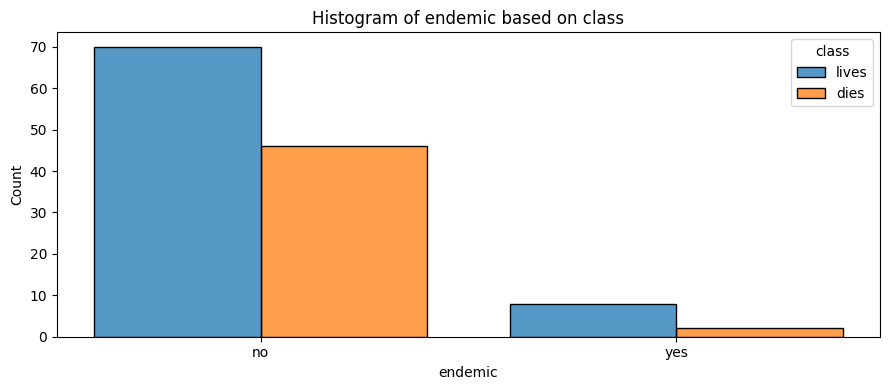

In [12]:
fe.fairness_profiler.plot_histogram(x="endemic", hue="class", multiple="dodge", figsize=(9, 4))

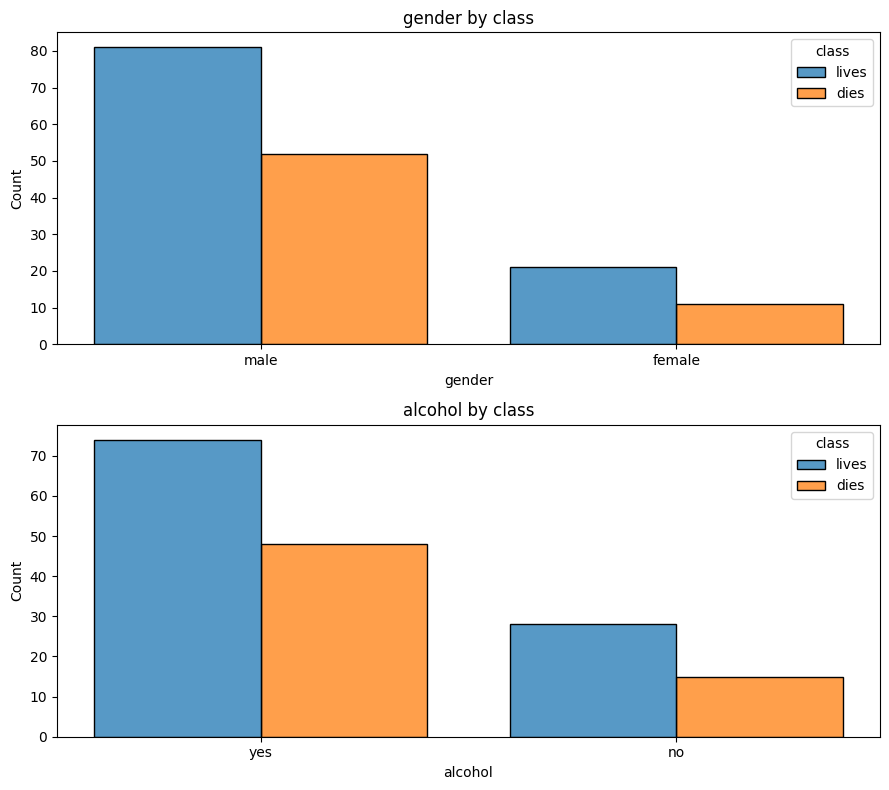

In [13]:
fe.fairness_profiler.plot_mult_histogram(col_names=["gender", "alcohol"], hue="class", cols=cols, subplot_size=(9,4))

## **Debug**

In [1]:
import sys
sys.path.append("../src")

from fairness import FairnessEngine
from utils import load_data

df = load_data("../data/hcc_dataset.csv")
fe = FairnessEngine(df, sensitive_features=["gender", "alcohol", "endemic"], target="class")

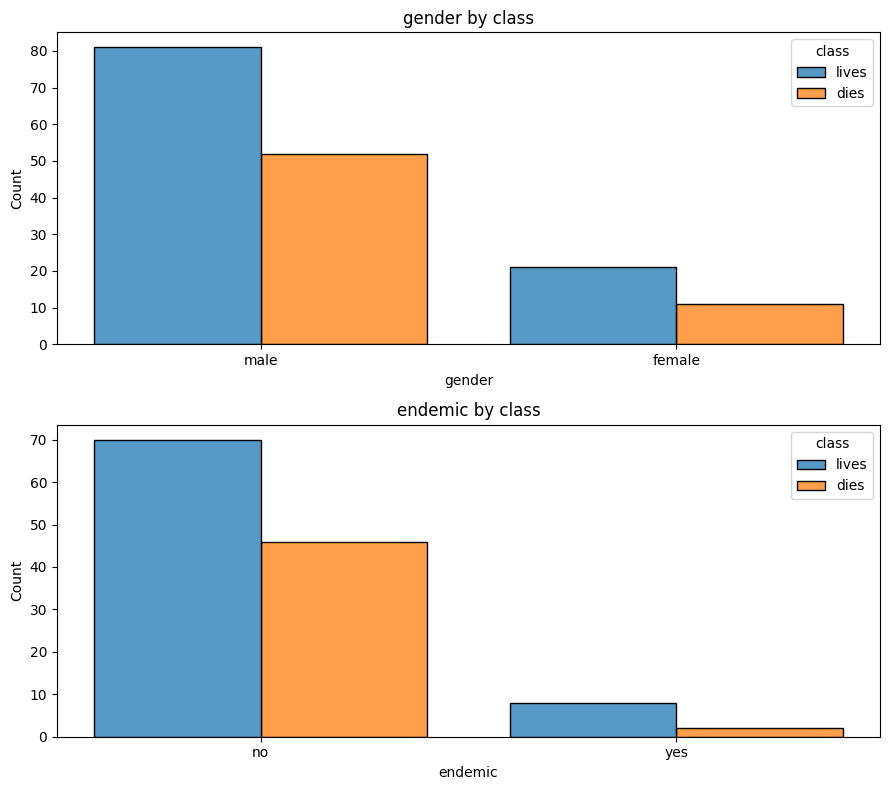

In [6]:
fe.plot_sensitive_groups(groups=["gender", "endemic"], target="class")

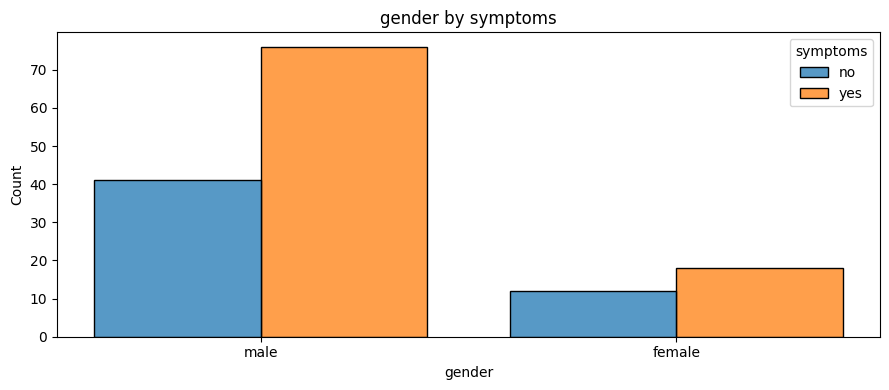

In [7]:
fe.plot_sensitive_groups(groups="gender", target="symptoms")

### **Implementation 3. Histogram of another feature by sensitive features (plot_feature_by_group) (this could include all groups)**

In [2]:
fe.get_sensitive_groups()

['gender',
 'alcohol',
 'endemic',
 'gender_alcohol',
 'gender_endemic',
 'alcohol_endemic',
 'gender_alcohol_endemic']

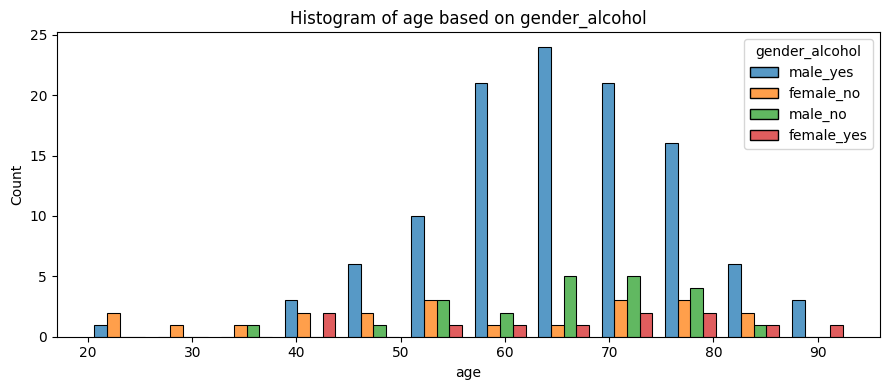

In [3]:
fe.fairness_profiler.plot_histogram(x="age", hue="gender_alcohol", multiple="dodge", figsize=(9, 4))

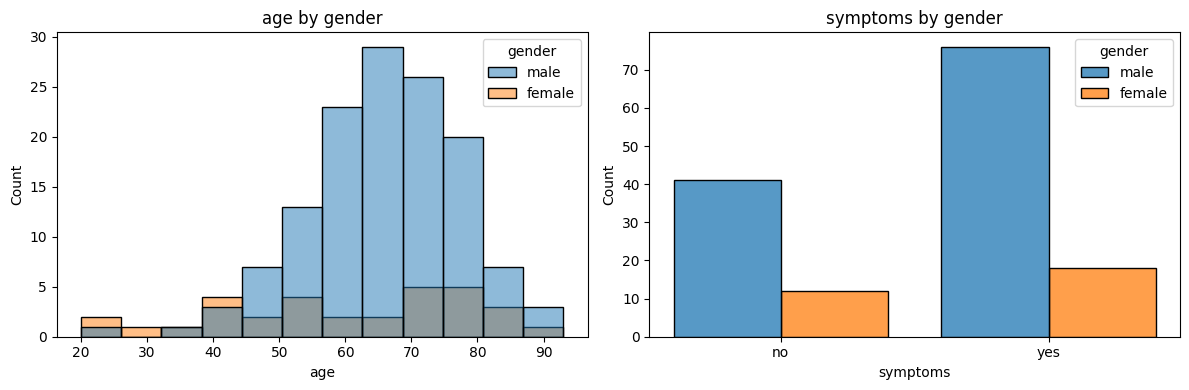

In [4]:
fe.fairness_profiler.plot_mult_histogram(col_names=["age", "symptoms"], hue="gender", cols=2, subplot_size=(6, 4))

In [13]:
groups=["gender"]
for group in groups:
    print(group)

gender


['age', 'symptoms']
gender


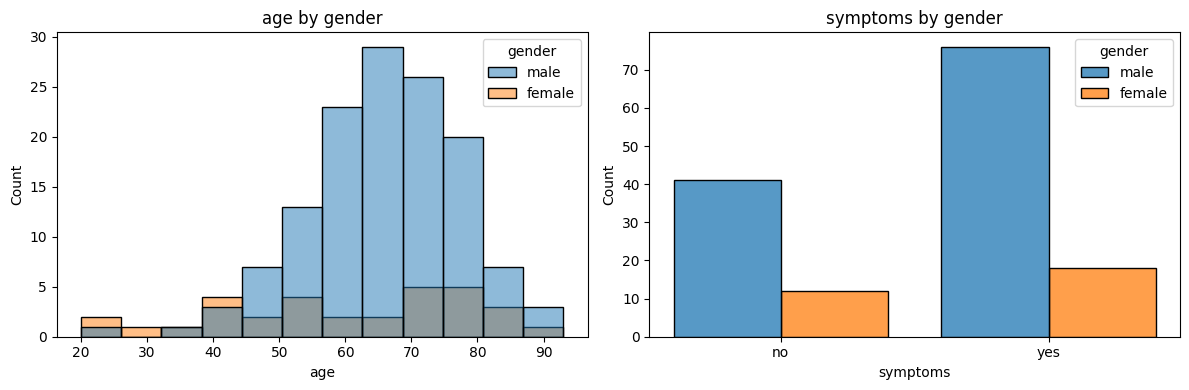

In [5]:
fe.plot_features_by_group(col_names=["age", "symptoms"], groups="gender")

['age']
gender


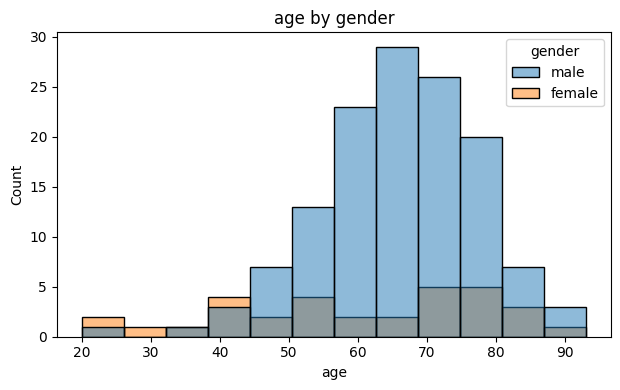

In [6]:
fe.plot_features_by_group(col_names="age", groups="gender")

['age']
gender_endemic


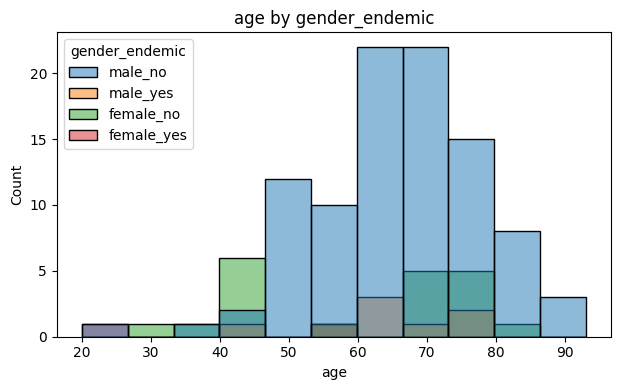

In [7]:
fe.plot_features_by_group(col_names="age", groups="gender_endemic")

['symptoms']
gender_endemic


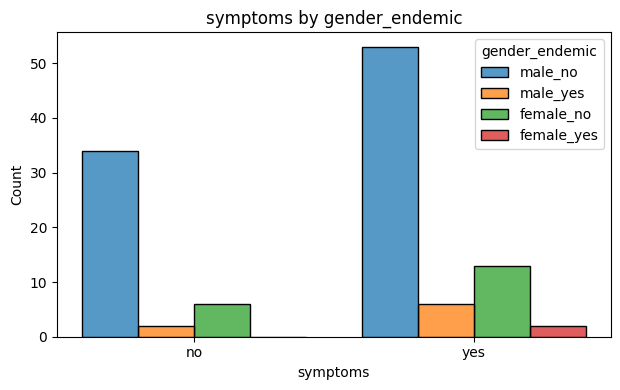

In [8]:
fe.plot_features_by_group(col_names="symptoms", groups="gender_endemic")

['symptoms', 'age']
gender


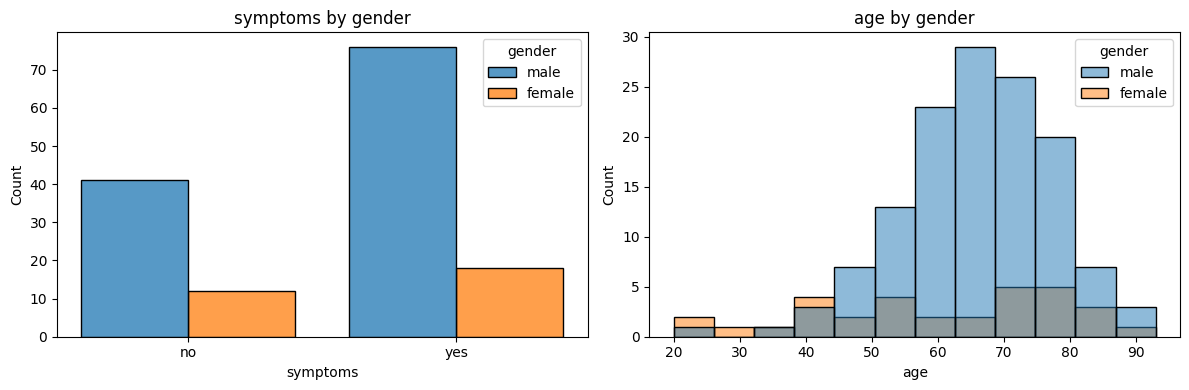

['symptoms', 'age']
alcohol


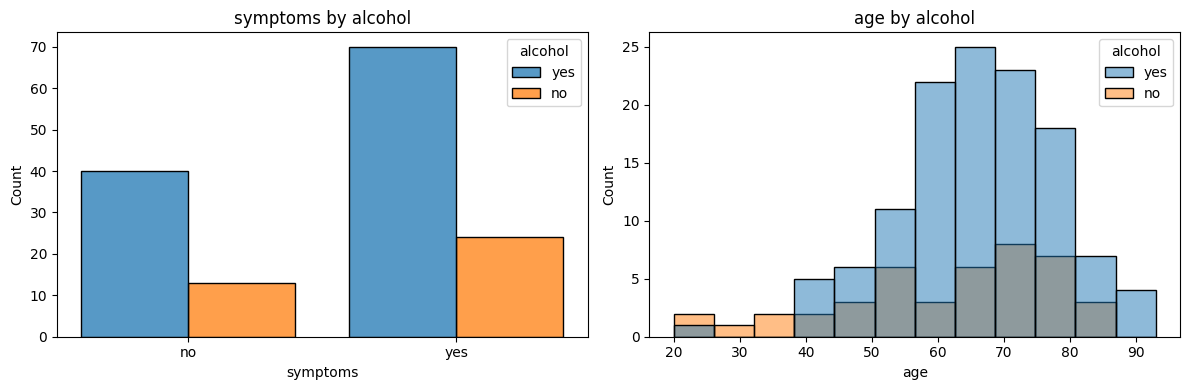

In [9]:
fe.plot_features_by_group(col_names=["symptoms", "age"], groups=["gender", "alcohol"])

['symptoms', 'age']
gender


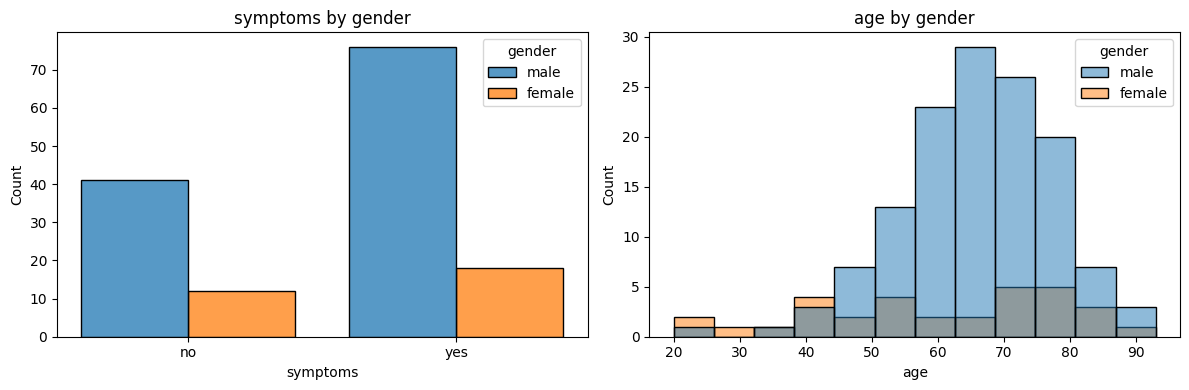

['symptoms', 'age']
alcohol


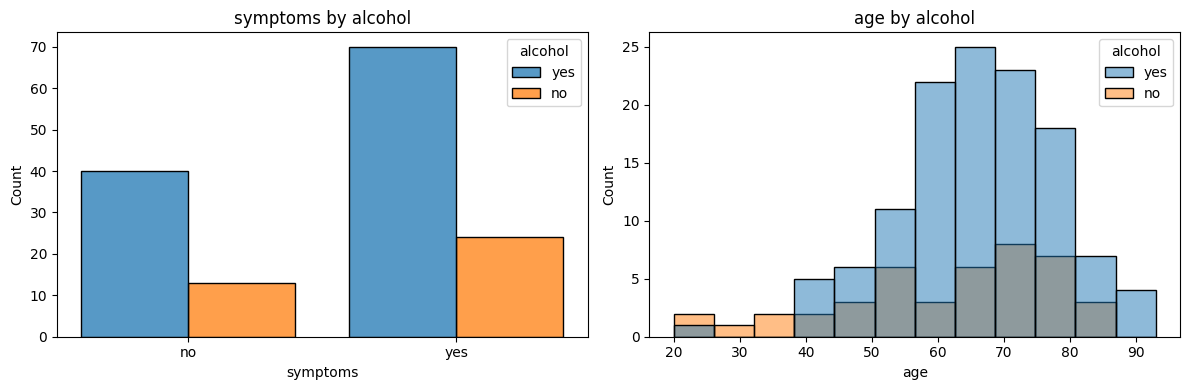

['symptoms', 'age']
endemic


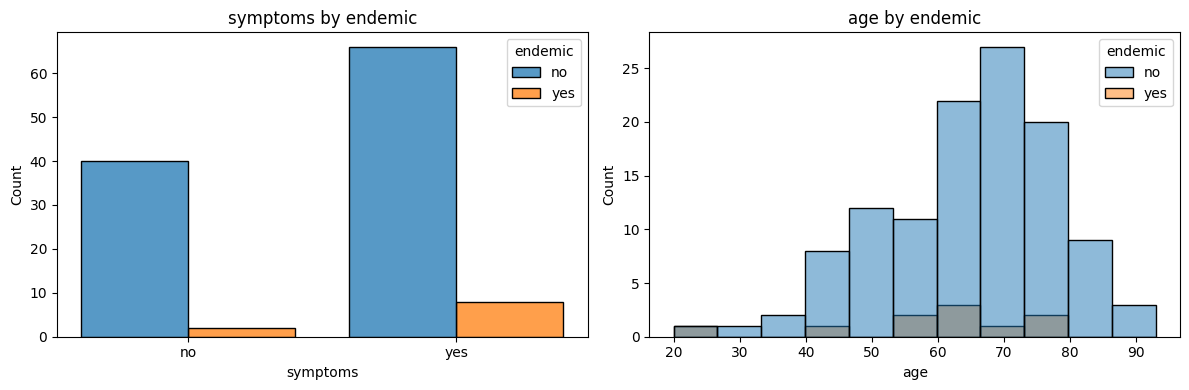

['symptoms', 'age']
gender_alcohol


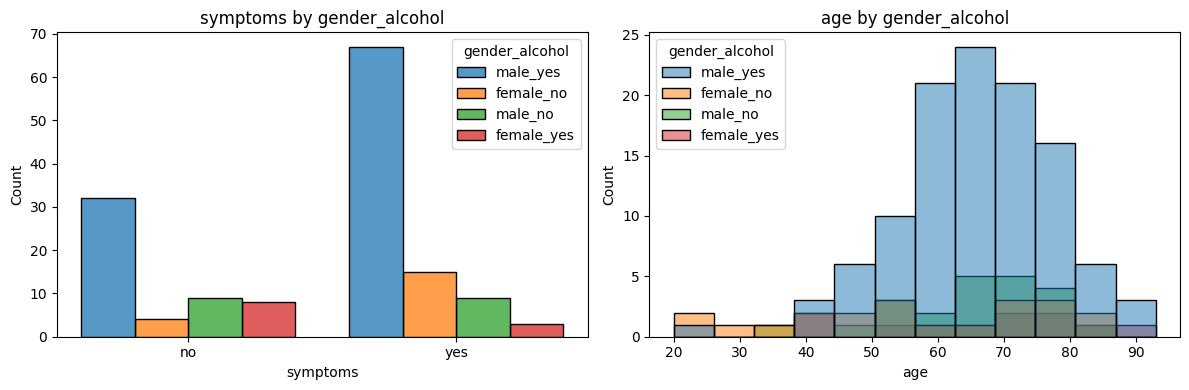

['symptoms', 'age']
gender_endemic


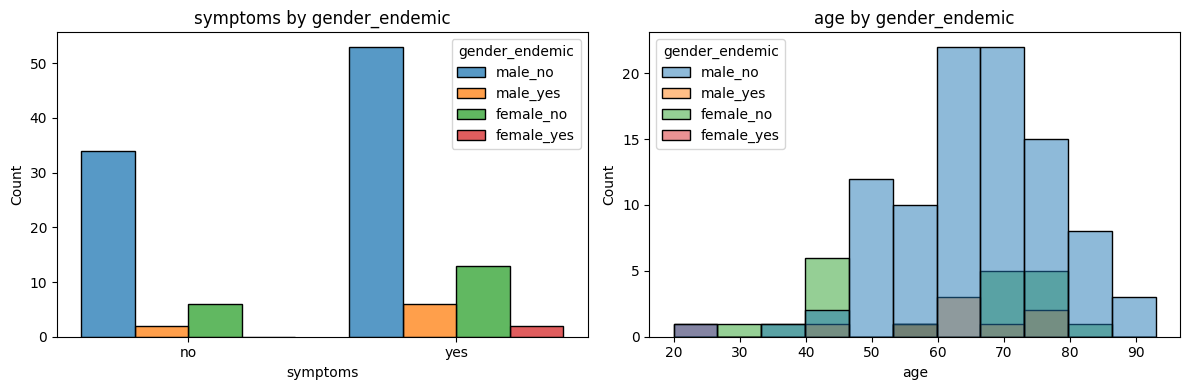

['symptoms', 'age']
alcohol_endemic


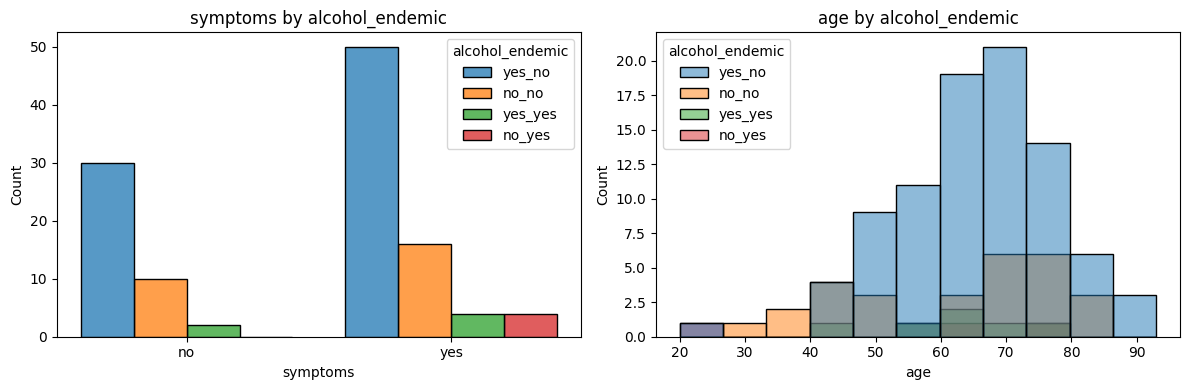

['symptoms', 'age']
gender_alcohol_endemic


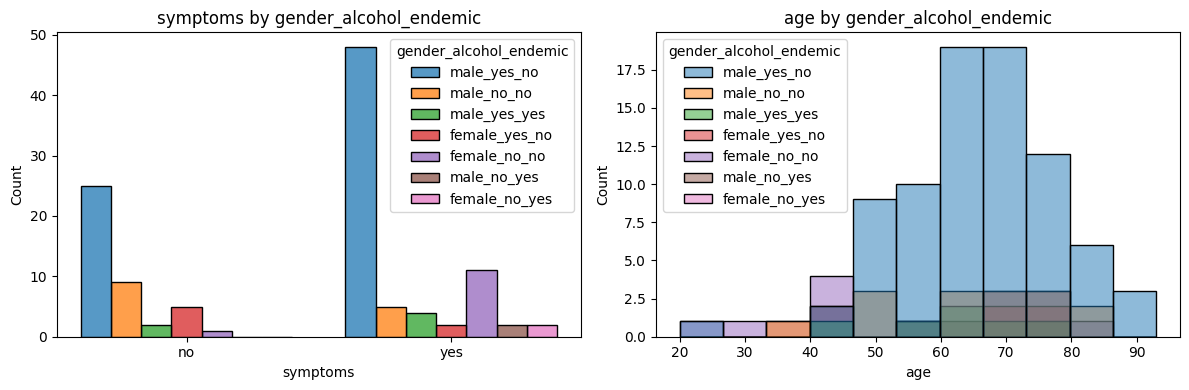

In [10]:
fe.plot_features_by_group(col_names=["symptoms", "age"], groups="all")